In [1]:
!kaggle datasets download architsharma01/loan-approval-prediction-dataset

Dataset URL: https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset
License(s): MIT
loan-approval-prediction-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [2]:
!unzip loan-approval-prediction-dataset.zip

Archive:  loan-approval-prediction-dataset.zip
replace loan_approval_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: loan_approval_dataset.csv  


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
data = pd.read_csv('loan_approval_dataset.csv')
df = pd.read_csv('loan_approval_dataset.csv')

In [5]:
df.columns = df.columns.str.strip()

In [7]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
loan_id,4269.0,2.135000e+03,1.232498e+03,1.0,1068.0,2135.0,3202.0,4269.0
no_of_dependents,4269.0,2.498712e+00,1.695910e+00,0.0,1.0,3.0,4.0,5.0
income_annum,4269.0,5.059124e+06,2.806840e+06,200000.0,2700000.0,5100000.0,7500000.0,9900000.0
loan_amount,4269.0,1.513345e+07,9.043363e+06,300000.0,7700000.0,14500000.0,21500000.0,39500000.0
loan_term,4269.0,1.090045e+01,5.709187e+00,2.0,6.0,10.0,16.0,20.0
cibil_score,4269.0,5.999361e+02,1.724304e+02,300.0,453.0,600.0,748.0,900.0
residential_assets_value,4269.0,7.472617e+06,6.503637e+06,-100000.0,2200000.0,5600000.0,11300000.0,29100000.0
commercial_assets_value,4269.0,4.973155e+06,4.388966e+06,0.0,1300000.0,3700000.0,7600000.0,19400000.0
luxury_assets_value,4269.0,1.512631e+07,9.103754e+06,300000.0,7500000.0,14600000.0,21700000.0,39200000.0
bank_asset_value,4269.0,4.976692e+06,3.250185e+06,0.0,2300000.0,4600000.0,7100000.0,14700000.0


In [9]:
df.drop('loan_id',axis=1,inplace=True)

In [10]:
df

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [11]:
df.isna().sum()

,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0
luxury_assets_value,0


cool,the data is clean and no duplicated

In [12]:
cat_cols = df.select_dtypes(include='object').columns
num_cols = df.select_dtypes(exclude='object').columns

In [13]:
cat_cols

Index(['education', 'self_employed', 'loan_status'], dtype='object')

In [14]:
num_cols

Index(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value'],
      dtype='object')

In [15]:
df

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [16]:
df.columns

Index(['no_of_dependents', 'education', 'self_employed', 'income_annum',
       'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status'],
      dtype='object')

In [17]:
df['loan_status'].nunique()

2

<Axes: xlabel='loan_status', ylabel='count'>

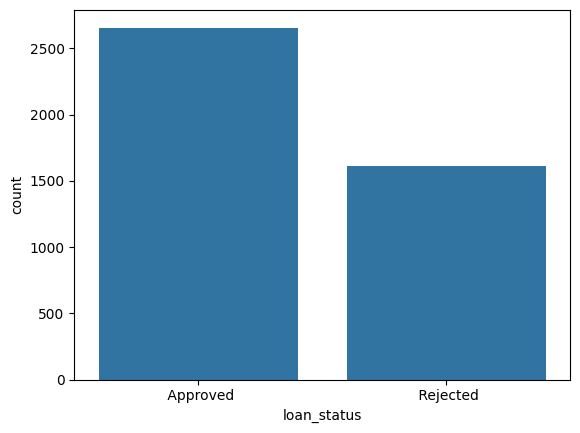

In [18]:
sns.countplot(x=df['loan_status'])

<Axes: xlabel='education', ylabel='count'>

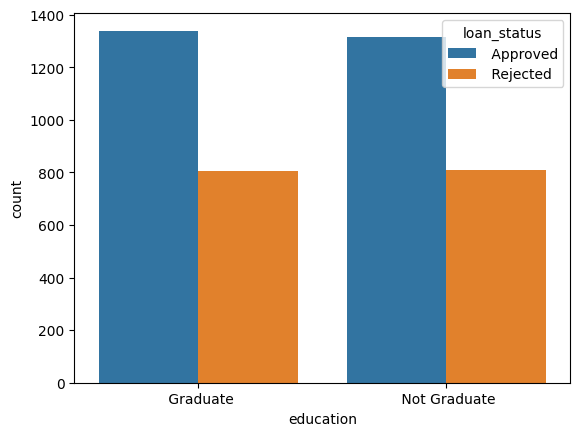

In [21]:
sns.countplot(df,x='education',hue='loan_status')

<Axes: xlabel='self_employed', ylabel='count'>

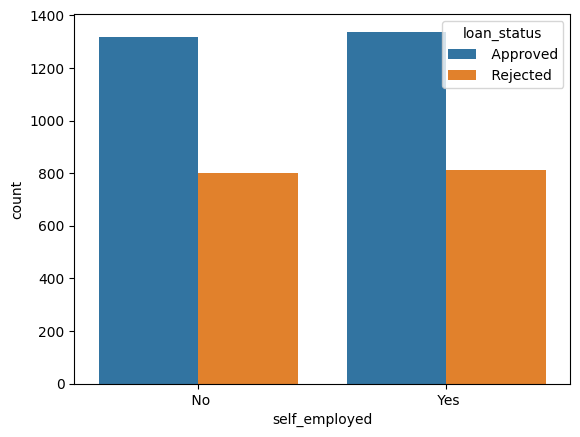

In [22]:
sns.countplot(df,x='self_employed',hue='loan_status')

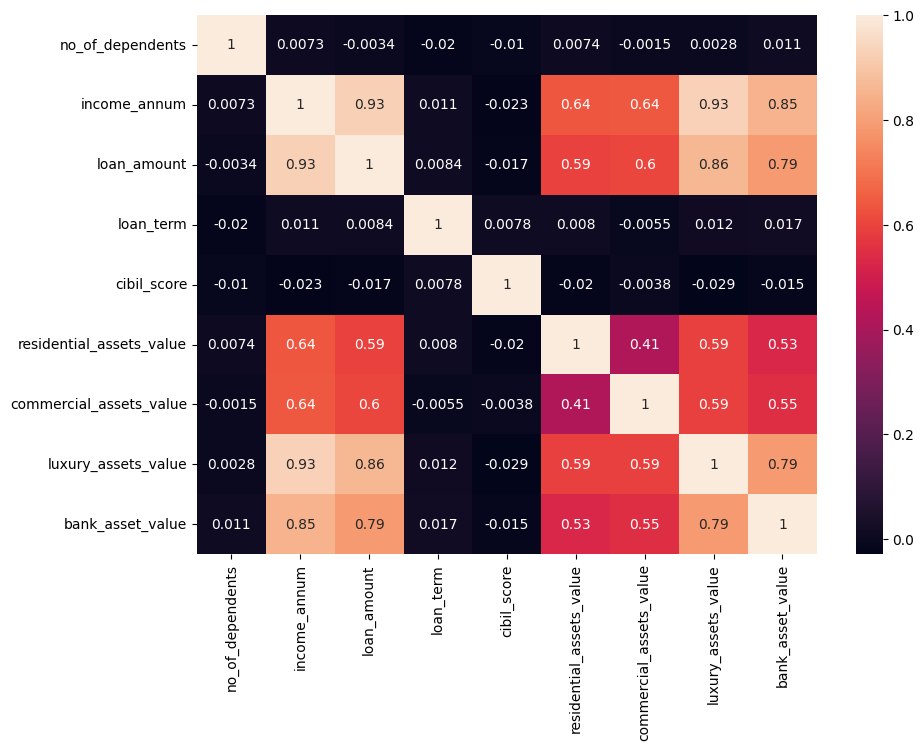

In [23]:
plt.figure(figsize = (10,7))
sns.heatmap(df[num_cols].corr(),annot = True,color="gold")
plt.show()

The correlation heatmap reveals strong positive correlations between some features, indicating potential multicollinearity.

1.Keep the highly correlated features initially. High correlation alone doesn't mean a feature must be removed.



2.Use StandardScaler for Logistic Regression.



3.Apply L2 Regularization (penalty='l2') to reduce the effect of correlated features.




In [24]:
num_cols

Index(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value'],
      dtype='object')

In [25]:
cat_cols

Index(['education', 'self_employed', 'loan_status'], dtype='object')

i will drop 'loan_status' so i can use cat_cols in training , and 'loan_status' is the target

In [26]:
cat_cols = cat_cols.drop('loan_status')

# **ML**

In [27]:
x = df.drop('loan_status',axis=1)
y = df['loan_status']

In [28]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [29]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((3415, 11), (854, 11), (3415,), (854,))

**Preprocessing**

In [30]:
num_cols

Index(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value'],
      dtype='object')

In [31]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

In [32]:
cat_cols

Index(['education', 'self_employed'], dtype='object')

In [33]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

x_train_encoded = ohe.fit_transform(x_train[cat_cols])
x_test_encoded = ohe.transform(x_test[cat_cols])

new_cols = ohe.get_feature_names_out(cat_cols)

x_train[new_cols] = x_train_encoded
x_test[new_cols] = x_test_encoded

x_train.drop(columns=cat_cols, inplace=True)
x_test.drop(columns=cat_cols, inplace=True)

In [34]:
x_train

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,education_ Graduate,education_ Not Graduate,self_employed_ No,self_employed_ Yes
1675,1.512508,1.009500,1.624772,-0.860003,-0.187401,-0.255384,2.046786,0.078083,1.160414,0.0,1.0,1.0,0.0
1164,-1.435001,1.614171,2.077128,0.188894,0.637397,2.495693,1.223111,2.498432,0.882020,0.0,1.0,0.0,1.0
192,-0.845499,-1.515891,-1.354157,-0.510371,0.474761,-0.805600,-0.881836,-1.339239,-1.314198,1.0,0.0,1.0,0.0
910,-0.255997,-0.057566,-0.228784,1.237791,0.892968,0.111426,-0.378479,0.143498,0.696424,1.0,0.0,0.0,1.0
567,1.512508,-0.733375,-0.449445,0.188894,-0.925072,0.157277,-0.561518,-0.859530,-0.912074,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3444,-1.435001,-1.338046,-1.155562,0.888158,-0.408121,-0.652762,-0.904716,-1.241117,-1.283266,1.0,0.0,0.0,1.0
466,1.512508,-1.622597,-1.475521,1.237791,-1.099324,-0.989005,-1.019115,-1.513678,-1.468862,0.0,1.0,0.0,1.0
3092,0.923006,1.258482,0.598697,0.888158,-0.878604,0.508804,1.291750,1.473599,0.139636,0.0,1.0,0.0,1.0
3772,-0.255997,0.689380,0.686961,0.188894,-0.344228,-0.576343,-0.836076,0.503279,1.438808,0.0,1.0,0.0,1.0


In [37]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

In [41]:
print(dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))

{' Approved': np.int64(0), ' Rejected': np.int64(1)}


**Logistic Regerssion**

In [42]:
from sklearn.linear_model import LogisticRegression

In [44]:
model = LogisticRegression(
   penalty="l2",
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    class_weight=None,
    random_state=42
)

In [45]:
model.fit(x_train,y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [46]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

In [47]:
y_train_proba = model.predict_proba(x_train)
y_test_proca = model.predict_proba(x_test)

In [50]:
model.feature_names_in_

array(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value',
       'bank_asset_value', 'education_ Graduate',
       'education_ Not Graduate', 'self_employed_ No',
       'self_employed_ Yes'], dtype=object)

In [48]:
model.coef_

array([[ 0.02972545,  1.62507888, -1.26934248,  0.8633507 , -4.16623826,
        -0.03536277, -0.0826061 , -0.27413758, -0.11327726, -0.02469762,
         0.01926015,  0.06312476, -0.06856223]])

In [51]:
model.intercept_

array([-1.73952778])

In [49]:
model.classes_

array([0, 1])

In [52]:
model.n_iter_

array([25], dtype=int32)

In [54]:
pd.DataFrame({"y_train_pred":y_train_pred,"y_train_act":y_train})

,y_train_pred,y_train_act
0,0,0
1,0,0
2,0,0
3,0,0
4,1,1
...,...,...
3410,1,1
3411,1,1
3412,1,1
3413,0,1


In [55]:
pd.DataFrame({"y_test_pred":y_test_pred,"y_test_act":y_test})

,y_test_pred,y_test_act
0,1,1
1,0,0
2,1,1
3,0,0
4,0,0
...,...,...
849,0,0
850,0,0
851,0,0
852,1,1


In [58]:
from sklearn.metrics import accuracy_score,confusion_matrix,recall_score,precision_score,f1_score,roc_auc_score,roc_auc_score,roc_curve

In [59]:
def evaluate_model(model, y_train, y_train_pred, y_test, y_test_pred):

    accuracy_train = accuracy_score(y_train, y_train_pred)
    recall_train = recall_score(y_train, y_train_pred)
    precision_train = precision_score(y_train, y_train_pred)
    f1_train = f1_score(y_train, y_train_pred)
    roc_auc_train = roc_auc_score(y_train, y_train_pred)

    print("-----Train-----")
    print("Accuracy:", accuracy_train)
    print("Recall:", recall_train)
    print("Precision:", precision_train)
    print("F1 Score:", f1_train)
    print("ROC AUC:", roc_auc_train)

    accuracy_test = accuracy_score(y_test, y_test_pred)
    recall_test = recall_score(y_test, y_test_pred)
    precision_test = precision_score(y_test, y_test_pred)
    f1_test = f1_score(y_test, y_test_pred)
    roc_auc_test = roc_auc_score(y_test, y_test_pred)

    print("\n-----Test-----")
    print("Accuracy:", accuracy_test)
    print("Recall:", recall_test)
    print("Precision:", precision_test)
    print("F1 Score:", f1_test)
    print("ROC AUC:", roc_auc_test)

    print("\n-----Confusion Matrix (Test)-----")
    print(confusion_matrix(y_test, y_test_pred))


In [60]:
evaluate_model(model, y_train, y_train_pred, y_test, y_test_pred)

-----Train-----
Accuracy: 0.9203513909224011
Recall: 0.894980694980695
Precision: 0.894980694980695
F1 Score: 0.894980694980695
ROC AUC: 0.9154148757922344

-----Test-----
Accuracy: 0.905152224824356
Recall: 0.8647798742138365
Precision: 0.8785942492012779
F1 Score: 0.8716323296354992
ROC AUC: 0.8969421759128883

-----Confusion Matrix (Test)-----
[[498  38]
 [ 43 275]]


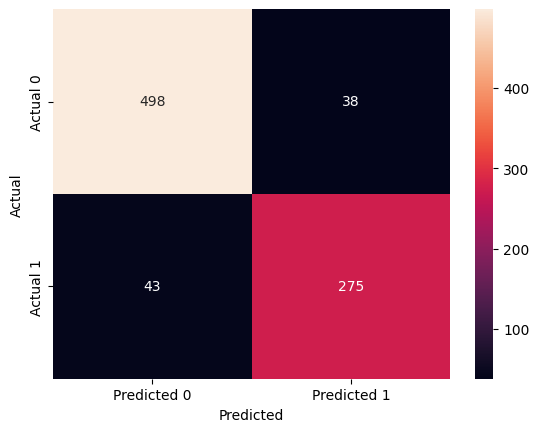

In [61]:
sns.heatmap(
    confusion_matrix(y_test, y_test_pred),
    annot=True,
    fmt="d",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

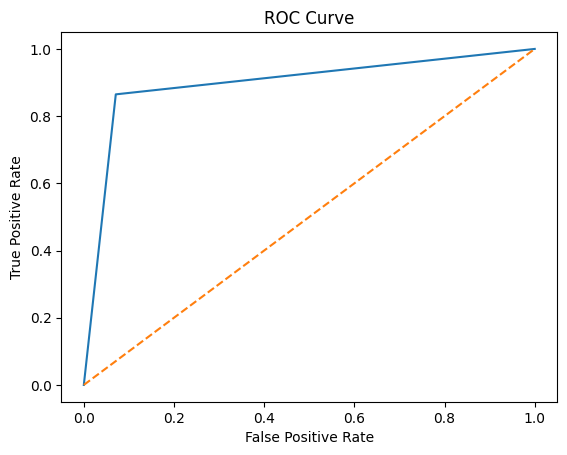

[inf  1.  0.]


In [63]:
fpr,tpr,thereshold = roc_curve(y_test,y_test_pred)
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1],linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()
print (thereshold)

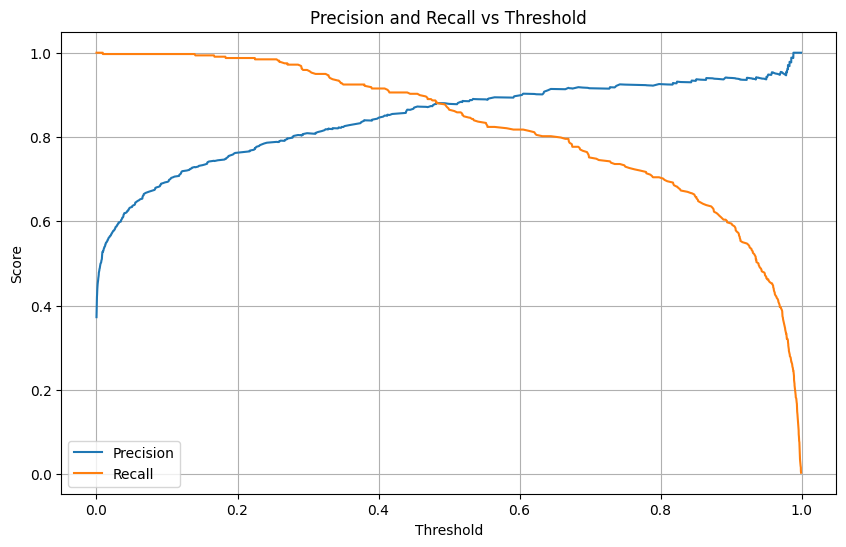

In [64]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

y_pred_proba = model.predict_proba(x_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test, y_pred_proba
)

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid()
plt.show()